<a href="https://colab.research.google.com/github/ons2006/World-Happiness-Report-2015/blob/main/happiness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Data Quality Assessment


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("2015.csv")
print("Dataset shape:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

print("Missing values:")
print(df.isnull().sum())

print("Data types:")
print(df.dtypes)


Dataset shape: (158, 12)
Duplicate rows: 0
Missing values:
Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Standard Error                   0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64
Data types:
Country                           object
Region                            object
Happiness Rank                     int64
Happiness Score                  float64
Standard Error                   float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Generosity                       float64
Dystopia Residual                float64
dtyp

In [ ]:
print(df.columns.tolist())

['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']


In [ ]:
df = df.drop_duplicates().dropna()
df.describe()

,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,79.493671,5.375734,0.047885,0.846137,0.991046,0.630259,0.428615,0.143422,0.237296,2.098977
std,45.754363,1.145010,0.017146,0.403121,0.272369,0.247078,0.150693,0.120034,0.126685,0.553550
min,1.000000,2.839000,0.018480,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.328580
25%,40.250000,4.526000,0.037268,0.545808,0.856823,0.439185,0.328330,0.061675,0.150553,1.759410
50%,79.500000,5.232500,0.043940,0.910245,1.029510,0.696705,0.435515,0.107220,0.216130,2.095415
75%,118.750000,6.243750,0.052300,1.158448,1.214405,0.811013,0.549092,0.180255,0.309883,2.462415
max,158.000000,7.587000,0.136930,1.690420,1.402230,1.025250,0.669730,0.551910,0.795880,3.602140


### 2. Happiness Ranking Analysis

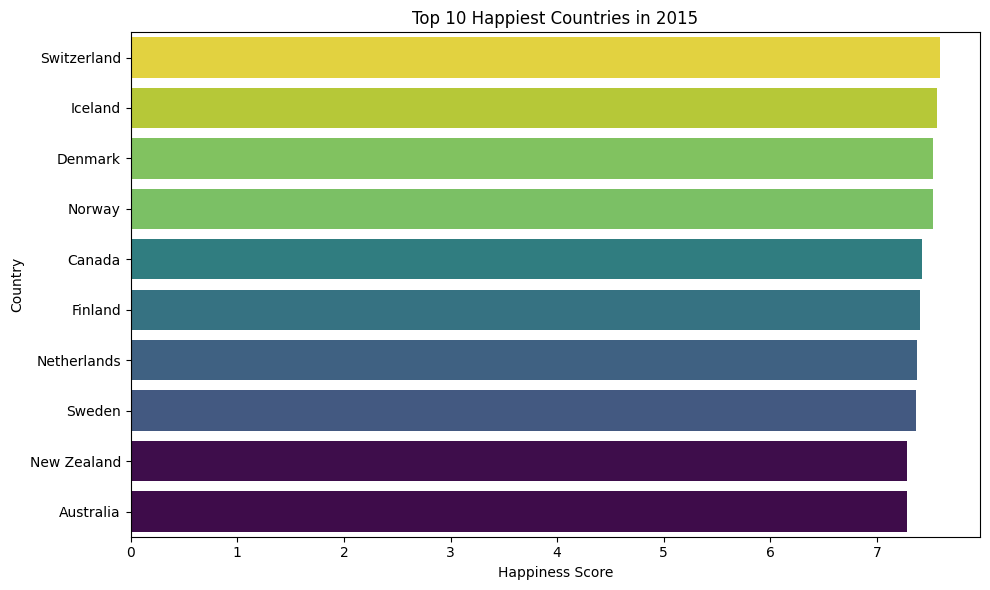

In [13]:
# Top 10 happiest countries
top_10 = df.nlargest(10, "Happiness Score")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10,
    x="Happiness Score",
    y="Country",
    hue="Happiness Score",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Happiest Countries in 2015")
plt.xlabel("Happiness Score")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

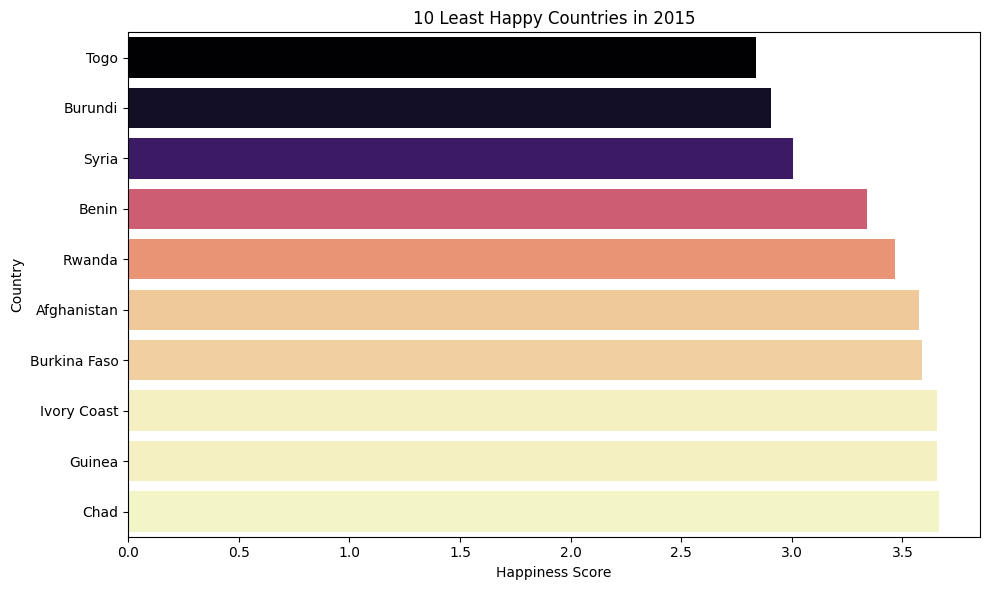

In [14]:
# Bottom 10 happiest countries
bottom_10 = df.nsmallest(10, "Happiness Score")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=bottom_10,
    x="Happiness Score",
    y="Country",
    hue="Happiness Score",
    palette="magma",
    legend=False
)

plt.title("10 Least Happy Countries in 2015")
plt.tight_layout()
plt.show()

### 3. Regional Happiness Analysis

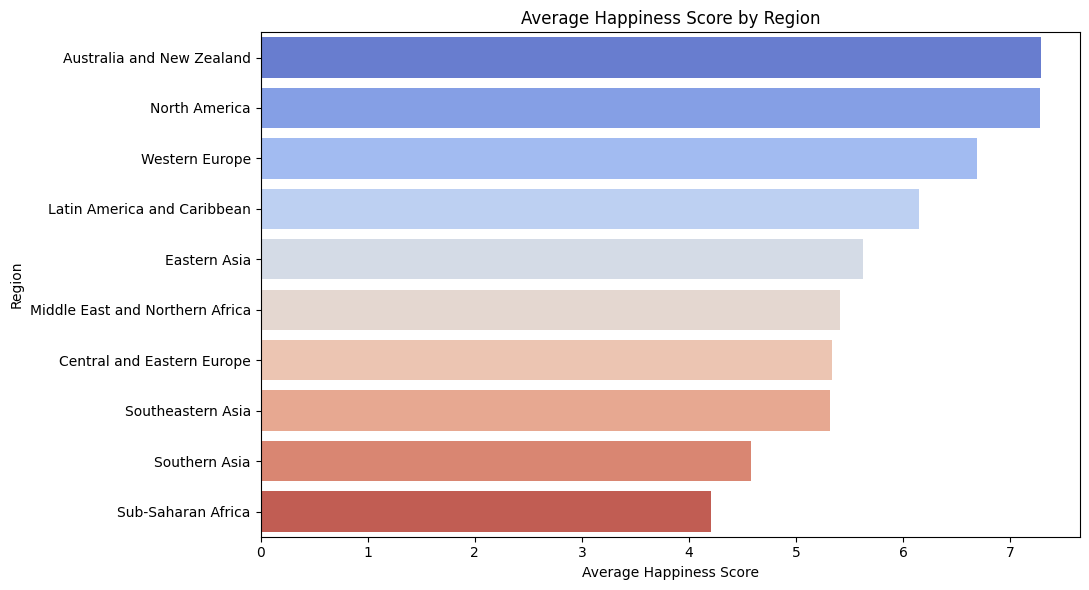

In [15]:
region_happiness = (
    df.groupby("Region")["Happiness Score"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=region_happiness.values,
    y=region_happiness.index,
    hue=region_happiness.index,
    palette="coolwarm",
    legend=False
)

plt.title("Average Happiness Score by Region")
plt.xlabel("Average Happiness Score")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

In [16]:
region_happiness

,Happiness Score
Region,
Australia and New Zealand,7.285000
North America,7.273000
Western Europe,6.689619
Latin America and Caribbean,6.144682
Eastern Asia,5.626167
Middle East and Northern Africa,5.406900
Central and Eastern Europe,5.332931
Southeastern Asia,5.317444
Southern Asia,4.580857


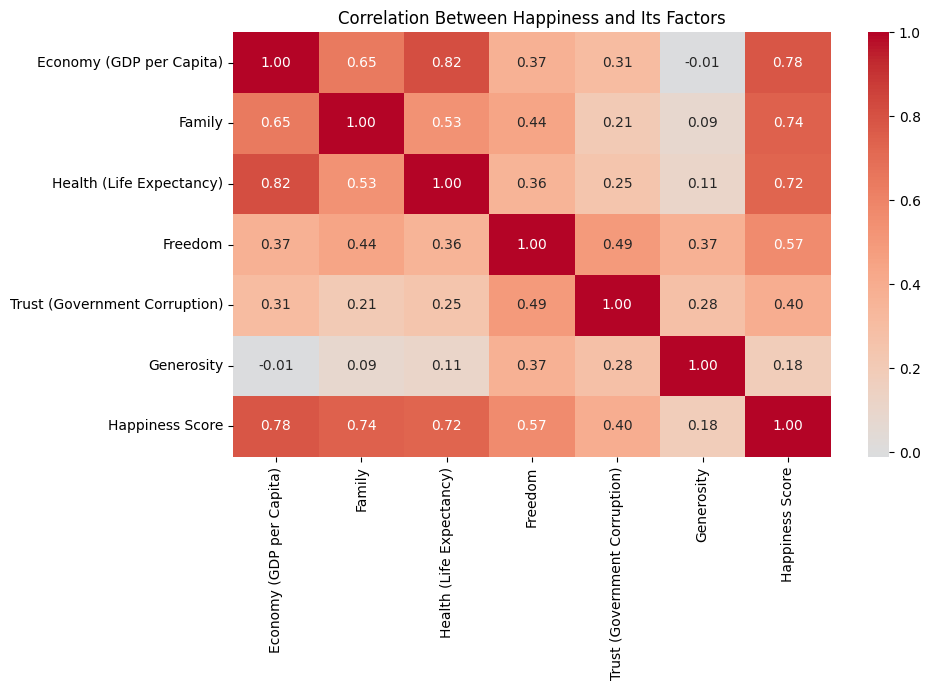

In [17]:
target = "Happiness Score"

features = [
    "Economy (GDP per Capita)",
    "Family",
    "Health (Life Expectancy)",
    "Freedom",
    "Trust (Government Corruption)",
    "Generosity"
]

correlation = df[features + [target]].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Happiness and Its Factors")
plt.tight_layout()
plt.show()

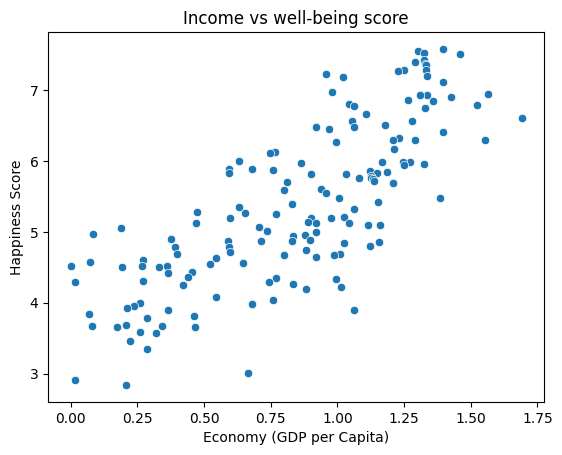

In [ ]:
gdp = [c for c in num.columns if "gdp" in c.lower()][0]
sns.scatterplot(data=num, x=gdp, y=target)
plt.title("Income vs well-being score")
plt.show()

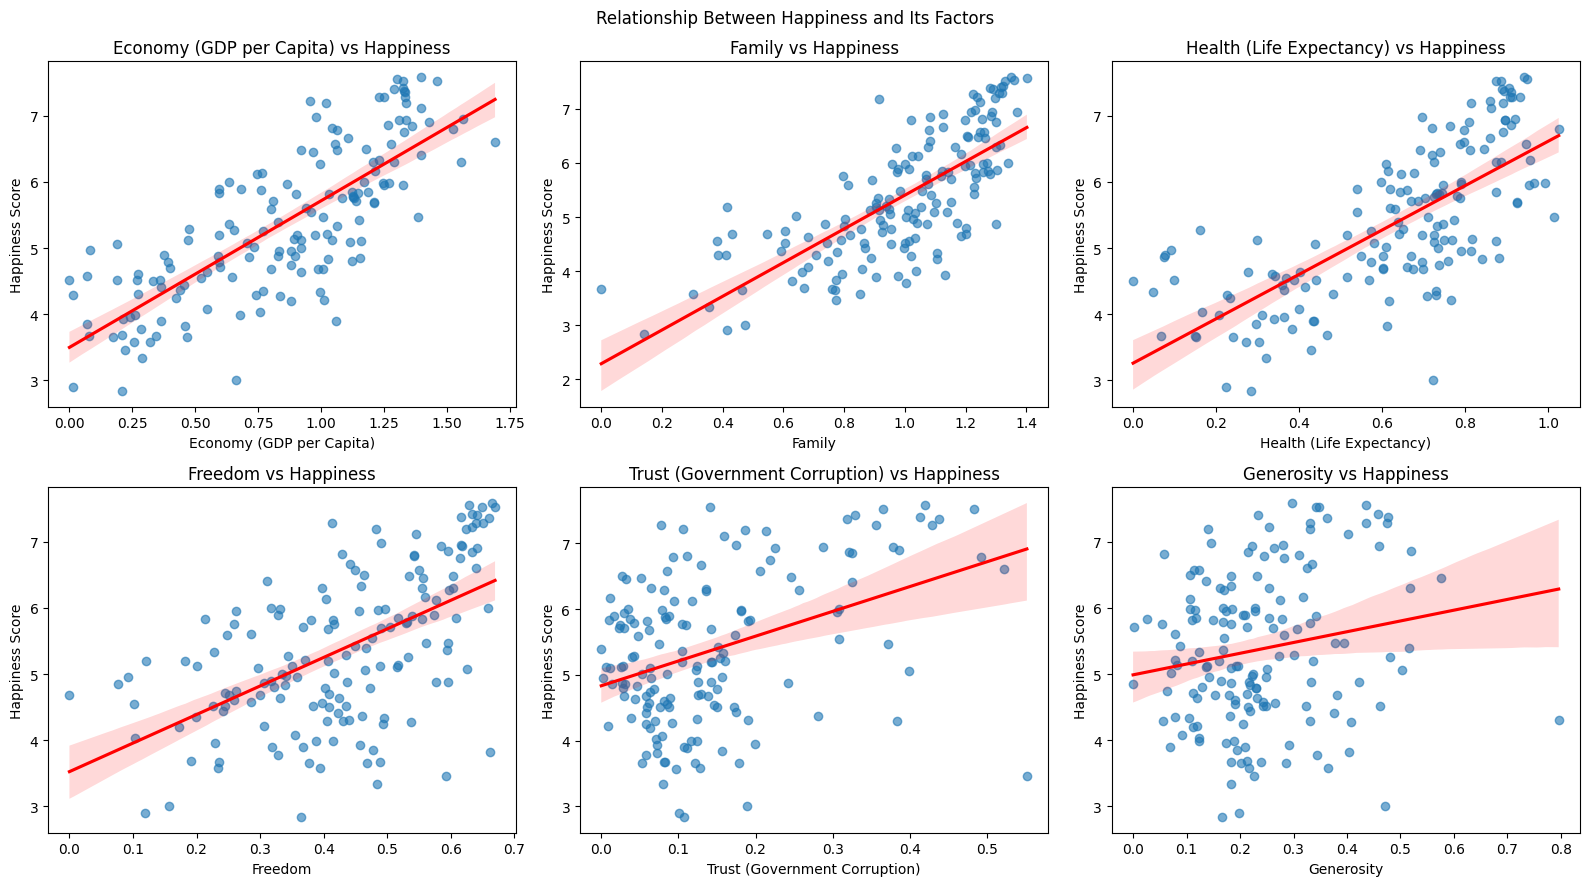

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flat, features):

    sns.regplot(
        data=df,
        x=feature,
        y=target,
        ax=ax,
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"}
    )

    ax.set_title(f"{feature} vs Happiness")

plt.suptitle("Relationship Between Happiness and Its Factors")
plt.tight_layout()
plt.show()

### 4. Machine Learning – Happiness Score Prediction

In [19]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Define features and target
X = df[features]
y = df["Happiness Score"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=4
    )
}

# Train and evaluate
for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    print("\n", name)
    print("R2 Score:", round(r2_score(y_test, predictions), 3))
    print("MAE:", round(mean_absolute_error(y_test, predictions), 3))
    print("RMSE:", round(mean_squared_error(
        y_test, predictions
    ) ** 0.5, 3))

    # 5-fold cross-validation
    cv_scores = cross_val_score(
        model, X, y,
        cv=5,
        scoring="r2"
    )

    print("Cross-validation R2:", round(cv_scores.mean(), 3))


 Linear Regression
R2 Score: 0.829
MAE: 0.402
RMSE: 0.492
Cross-validation R2: -5.827

 Random Forest
R2 Score: 0.81
MAE: 0.426
RMSE: 0.519
Cross-validation R2: -8.423


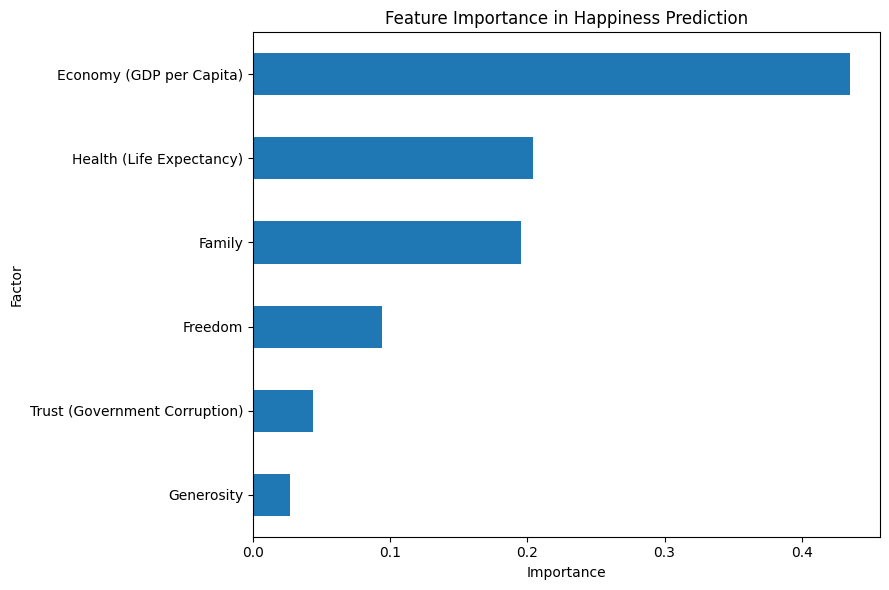

In [20]:
rf = models["Random Forest"]

importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))

importance.plot(kind="barh")

plt.title("Feature Importance in Happiness Prediction")
plt.xlabel("Importance")
plt.ylabel("Factor")

plt.tight_layout()
plt.show()